# Detecting Malicious Network Connections with Python

**Goal:** load the NSL-KDD intrusion dataset, clean it, explore it, and build a simple detector that labels each network connection as **normal (0)** or **attack (1)**. Then find out where the detector fails, and why.

**Dataset:** NSL-KDD (Tavallaee, Bagheri, Lu & Ghorbani, 2009), `KDDTrain+.txt` and `KDDTest+.txt`, retrieved from https://github.com/jmnwong/NSL-KDD-Dataset.

Cells marked **(Optional)** add charts and extra checks. The notebook runs without them, but the README charts come from them.

## Phase 0: Setup

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)

print("pandas", pd.__version__, "| scikit-learn", sklearn.__version__)  # check the venv is wired up

pandas 3.0.3 | scikit-learn 1.9.0


In [2]:
# Relative paths: this notebook lives in /notebook, the data in /data, so it runs on any computer
DATA_DIR = Path("..") / "data"
IMG_DIR = Path("..") / "images"
IMG_DIR.mkdir(exist_ok=True)      # charts for the README are saved here

pd.set_option("display.max_columns", None)   # show every column in .head() and .describe()

## Phase 1: Load and understand the training data

The files have no header row, so I supply the 43 column names myself: 41 traffic features, then `label` (the attack name) and `difficulty` (a score the dataset authors added).

In [3]:
col_names = ['duration', 'protocol_type', 'service', 'flag', 'src_bytes', 'dst_bytes', 'land',
             'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'logged_in', 'num_compromised',
             'root_shell', 'su_attempted', 'num_root', 'num_file_creations', 'num_shells',
             'num_access_files', 'num_outbound_cmds', 'is_host_login', 'is_guest_login', 'count',
             'srv_count', 'serror_rate', 'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate',
             'same_srv_rate', 'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count',
             'dst_host_srv_count', 'dst_host_same_srv_rate', 'dst_host_diff_srv_rate',
             'dst_host_same_src_port_rate', 'dst_host_srv_diff_host_rate', 'dst_host_serror_rate',
             'dst_host_srv_serror_rate', 'dst_host_rerror_rate', 'dst_host_srv_rerror_rate',
             'label', 'difficulty']
len(col_names)   # expect 43

43

In [4]:
train = pd.read_csv(DATA_DIR / "KDDTrain+.txt", header=None, names=col_names)  # header=None: the file has no header row
train.shape   # expect (125973, 43)

(125973, 43)

In [5]:
train.head()

,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,num_failed_logins,logged_in,num_compromised,root_shell,su_attempted,num_root,num_file_creations,num_shells,num_access_files,num_outbound_cmds,is_host_login,is_guest_login,count,srv_count,serror_rate,srv_serror_rate,rerror_rate,srv_rerror_rate,same_srv_rate,diff_srv_rate,srv_diff_host_rate,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,difficulty
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2,2,0.0,0.0,0.0,0.0,1.00,0.00,0.00,150,25,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,13,1,0.0,0.0,0.0,0.0,0.08,0.15,0.00,255,1,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,123,6,1.0,1.0,0.0,0.0,0.05,0.07,0.00,255,26,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19
3,0,tcp,http,SF,232,8153,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,5,5,0.2,0.2,0.0,0.0,1.00,0.00,0.00,30,255,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21
4,0,tcp,http,SF,199,420,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,30,32,0.0,0.0,0.0,0.0,1.00,0.00,0.09,255,255,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21


In [6]:
train.info()   # 43 columns, no missing values, 4 text columns (protocol_type, service, flag, label)

<class 'pandas.DataFrame'>
RangeIndex: 125973 entries, 0 to 125972
Data columns (total 43 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   duration                     125973 non-null  int64  
 1   protocol_type                125973 non-null  str    
 2   service                      125973 non-null  str    
 3   flag                         125973 non-null  str    
 4   src_bytes                    125973 non-null  int64  
 5   dst_bytes                    125973 non-null  int64  
 6   land                         125973 non-null  int64  
 7   wrong_fragment               125973 non-null  int64  
 8   urgent                       125973 non-null  int64  
 9   hot                          125973 non-null  int64  
 10  num_failed_logins            125973 non-null  int64  
 11  logged_in                    125973 non-null  int64  
 12  num_compromised              125973 non-null  int64  
 13  root_shell

In [7]:
train['label'].value_counts()   # 'neptune' (a SYN-flood DoS attack) is the most common attack

label
normal             67343
neptune            41214
satan               3633
ipsweep             3599
portsweep           2931
smurf               2646
nmap                1493
back                 956
teardrop             892
warezclient          890
pod                  201
guess_passwd          53
buffer_overflow       30
warezmaster           20
land                  18
imap                  11
rootkit               10
loadmodule             9
ftp_write              8
multihop               7
phf                    4
perl                   3
spy                    2
Name: count, dtype: int64

### Create the target: normal = 0, attack = 1

In [8]:
# != gives True for every attack; .astype(int) turns True/False into 1/0
train['target'] = (train['label'] != 'normal').astype(int)
train['target'].value_counts()   # expect 0: 67,343 and 1: 58,630

target
0    67343
1    58630
Name: count, dtype: int64

### Map the 22 attack names to four families

- **DoS** (denial of service) floods a target. **Probe** scans for information. Both are loud and high-volume.
- **R2L** (remote to local) and **U2R** (user to root) are quiet: often one connection, with the harm hidden in the payload.

In [9]:
attack_map = {
    # DoS: exhaust a resource so legitimate users can't get service
    "neptune": "DoS",          # SYN flood: half-open TCP connections fill the target's connection table
    "smurf": "DoS",            # ICMP amplification: spoofed pings to a broadcast address drown the victim
    "back": "DoS",             # malformed requests that slow a web server to a crawl
    "teardrop": "DoS",         # overlapping IP fragments crash the target's reassembly routine
    "pod": "DoS",              # "ping of death": oversized ICMP packet crashes the host
    "land": "DoS",             # spoofed packet with source = destination locks the machine in a loop

    # Probe: gather information about the network, no access attempted yet
    "satan": "Probe",          # automated scanner looking for known vulnerabilities
    "ipsweep": "Probe",        # pings a range of addresses to find live hosts
    "portsweep": "Probe",      # scans many ports on a host to find open services
    "nmap": "Probe",           # general-purpose port and host scanner

    # R2L: an outside attacker with no account gains local access
    "guess_passwd": "R2L",     # repeated logins to guess credentials
    "warezclient": "R2L",      # downloads illegal files planted on an FTP server
    "warezmaster": "R2L",      # uploads illegal files by abusing FTP write permissions
    "imap": "R2L",             # exploits a vulnerable IMAP mail server
    "ftp_write": "R2L",        # abuses a writable anonymous FTP directory
    "multihop": "R2L",         # multi-stage attack chained through intermediate hosts
    "phf": "R2L",              # exploits a vulnerable CGI script to run commands remotely
    "spy": "R2L",              # stealthy long-term access and data exfiltration

    # U2R: an attacker with a user account escalates to root
    "buffer_overflow": "U2R",  # overflows a buffer in a privileged program to run code as root
    "rootkit": "U2R",          # installs tools that hide the attacker while keeping root
    "loadmodule": "U2R",       # abuses a privileged system utility to obtain root
    "perl": "U2R",             # abuses a setuid Perl script to gain root

    "normal": "normal",        # legitimate traffic
}

In [10]:
train['attack_category'] = train['label'].map(attack_map)   # .map() looks each label up in the dictionary
train['attack_category'].value_counts(dropna=False)         # dropna=False shows NaN if any label is missing from the map

attack_category
normal    67343
DoS       45927
Probe     11656
R2L         995
U2R          52
Name: count, dtype: int64

## Phase 2: Clean

Check for missing values and duplicates, then look for columns that never change (zero variance), because a model can't learn from them.

In [11]:
# (Optional) Data-quality checks: expect 0 missing values and 0 duplicate rows (NSL-KDD's authors removed duplicates)
print("Missing values:", train.isna().sum().sum())
print("Duplicate rows:", train.duplicated().sum())

Missing values: 0
Duplicate rows: 0


In [12]:
train.describe().T   # .T flips the table so each feature is one row; look for min = max = 0

,count,mean,std,min,25%,50%,75%,max
duration,125973.0,287.144650,2.604515e+03,0.0,0.00,0.00,0.00,4.290800e+04
src_bytes,125973.0,45566.743000,5.870331e+06,0.0,0.00,44.00,276.00,1.379964e+09
dst_bytes,125973.0,19779.114421,4.021269e+06,0.0,0.00,0.00,516.00,1.309937e+09
land,125973.0,0.000198,1.408607e-02,0.0,0.00,0.00,0.00,1.000000e+00
wrong_fragment,125973.0,0.022687,2.535300e-01,0.0,0.00,0.00,0.00,3.000000e+00
urgent,125973.0,0.000111,1.436603e-02,0.0,0.00,0.00,0.00,3.000000e+00
hot,125973.0,0.204409,2.149968e+00,0.0,0.00,0.00,0.00,7.700000e+01
num_failed_logins,125973.0,0.001222,4.523914e-02,0.0,0.00,0.00,0.00,5.000000e+00
logged_in,125973.0,0.395736,4.890101e-01,0.0,0.00,0.00,1.00,1.000000e+00
num_compromised,125973.0,0.279250,2.394204e+01,0.0,0.00,0.00,0.00,7.479000e+03


In [13]:
# Show only the numeric columns whose maximum is 0, i.e. columns that are always 0
max_vals = train.max(numeric_only=True)
max_vals[max_vals == 0]   # expect: num_outbound_cmds

num_outbound_cmds    0.0
dtype: float64

In [14]:
train = train.drop(columns=['num_outbound_cmds'])   # constant zeros: no information for the model
train.shape   # expect (125973, 44): 43 + target + attack_category - 1 dropped

(125973, 44)

In [15]:
# The three text features must be encoded before modelling. How many categories does each have?
train[['protocol_type', 'flag', 'service']].nunique()   # expect 3, 11, 70

protocol_type     3
flag             11
service          70
dtype: int64

In [16]:
train['flag'].value_counts()   # TCP connection states: SF = normal completed connection, S0 = no reply (SYN flood sign)

flag
SF        74945
S0        34851
REJ       11233
RSTR       2421
RSTO       1562
S1          365
SH          271
S2          127
RSTOS0      103
S3           49
OTH          46
Name: count, dtype: int64

## Phase 3: Explore and visualise (Optional)

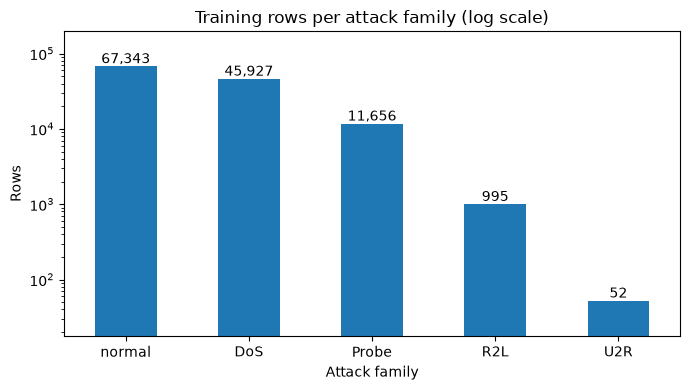

In [17]:
# (Optional) Rows per attack family, on a log scale so the rare families are visible
family_counts = train['attack_category'].value_counts().reindex(['normal', 'DoS', 'Probe', 'R2L', 'U2R'])

ax = family_counts.plot.bar(logy=True, figsize=(7, 4), rot=0)
ax.set_title("Training rows per attack family (log scale)")
ax.set_ylabel("Rows")
ax.set_xlabel("Attack family")
ax.margins(y=0.15)
ax.bar_label(ax.containers[0], fmt="{:,.0f}")
plt.tight_layout()
plt.savefig(IMG_DIR / "train_families.png", dpi=150)
plt.show()

In [18]:
# (Optional) Share of attacks for each connection flag: this is where the rule baseline in Phase 7 comes from
flag_attack_share = train.groupby('flag')['target'].agg(['mean', 'count']).sort_values('count', ascending=False)
flag_attack_share.rename(columns={'mean': 'share_attacks', 'count': 'rows'})

,share_attacks,rows
flag,,
SF,0.154140,74945
S0,0.989842,34851
REJ,0.760260,11233
RSTR,0.939694,2421
RSTO,0.859795,1562
S1,0.010959,365
SH,0.992620,271
S2,0.062992,127
RSTOS0,1.000000,103


## Phase 4: Prepare the test set the same way

The test file contains **17 attack types that never appear in training**. They test whether the detector can spot attacks it has never seen.

In [19]:
test = pd.read_csv(DATA_DIR / "KDDTest+.txt", header=None, names=col_names)
test.shape   # expect (22544, 43)

(22544, 43)

In [20]:
test['target'] = (test['label'] != 'normal').astype(int)
test['target'].value_counts()   # expect 1: 12,833 and 0: 9,711

target
1    12833
0     9711
Name: count, dtype: int64

In [21]:
test['attack_category'] = test['label'].map(attack_map)
test['attack_category'].value_counts(dropna=False)   # NaN = 3,750 rows whose attack name isn't in the map yet

attack_category
normal    9711
DoS       5741
NaN       3750
R2L       2199
Probe     1106
U2R         37
Name: count, dtype: int64

In [22]:
# Which attack names are unknown? (only the rows where .map() wrote NaN)
test.loc[test['attack_category'].isna(), 'label'].value_counts()   # 17 new names, 3,750 rows

label
mscan            996
apache2          737
processtable     685
snmpguess        331
saint            319
mailbomb         293
snmpgetattack    178
httptunnel       133
named             17
ps                15
sendmail          14
xterm             13
xlock              9
xsnoop             4
worm               2
sqlattack          2
udpstorm           2
Name: count, dtype: int64

In [23]:
# Add the 17 test-only attack types to their families (standard NSL-KDD grouping)
attack_map.update({
    # DoS
    'apache2': 'DoS', 'processtable': 'DoS', 'mailbomb': 'DoS', 'udpstorm': 'DoS',
    # Probe
    'mscan': 'Probe', 'saint': 'Probe',
    # R2L (some papers put httptunnel under U2R)
    'snmpguess': 'R2L', 'snmpgetattack': 'R2L', 'httptunnel': 'R2L', 'named': 'R2L',
    'sendmail': 'R2L', 'xlock': 'R2L', 'xsnoop': 'R2L', 'worm': 'R2L',
    # U2R
    'ps': 'U2R', 'xterm': 'U2R', 'sqlattack': 'U2R',
})

test['attack_category'] = test['label'].map(attack_map)   # re-run the map with the updated dictionary
test['attack_category'].value_counts(dropna=False)         # expect no NaN: normal 9,711, DoS 7,458, R2L 2,887, Probe 2,421, U2R 67

attack_category
normal    9711
DoS       7458
R2L       2887
Probe     2421
U2R         67
Name: count, dtype: int64

In [24]:
test = test.drop(columns=['num_outbound_cmds'])   # same treatment as train (it is all zeros in test too)
test.shape   # expect (22544, 44)

(22544, 44)

## Phase 5: Encode the text columns (one-hot encoding)

Each category becomes its own True/False column. `service` has 70 values, so it adds 70 columns. That's acceptable for tree models with 125,973 rows.

In [25]:
cat_cols = ['protocol_type', 'flag', 'service']
train_encoded = pd.get_dummies(train, columns=cat_cols)
test_encoded = pd.get_dummies(test, columns=cat_cols)

print(train_encoded.shape, test_encoded.shape)   # train: 44 - 3 + 84 = 125 columns; test has fewer (some services never appear in it)

(125973, 125) (22544, 119)


In [26]:
# Give test exactly train's columns in train's order; categories missing from test are filled with 0
test_encoded = test_encoded.reindex(columns=train_encoded.columns, fill_value=0)

list(train_encoded.columns) == list(test_encoded.columns)   # expect True (same names AND same order)

True

In [27]:
# Every row must have exactly one True per original column, e.g. one protocol per connection
for prefix in ['protocol_type_', 'flag_', 'service_']:
    print(prefix, train_encoded.filter(like=prefix).sum(axis=1).value_counts().to_dict())   # expect {1: 125973}

protocol_type_ {1: 125973}
flag_ {1: 125973}
service_ {1: 125973}


## Phase 6: Split into features (X) and target (y)

`label` and `attack_category` are the answer in other words, and `difficulty` is metadata added by the dataset authors. Leaving any of them in would be **data leakage**.

In [28]:
drop_cols = ['label', 'attack_category', 'target', 'difficulty']

X_train = train_encoded.drop(columns=drop_cols)
y_train = train_encoded['target']
X_test = test_encoded.drop(columns=drop_cols)
y_test = test_encoded['target']

print(X_train.shape, X_test.shape)    # expect (125973, 121) (22544, 121)
print(X_train.dtypes.value_counts())  # expect only bool, int64, float64 (no text left)

(125973, 121) (22544, 121)
bool       84
int64      22
float64    15
Name: count, dtype: int64


## Phase 7: Rule baseline (Optional)

Before any machine learning: how far does one rule get? In training, almost every connection with a flag other than `SF` (a normal, completed connection) is an attack.

In [29]:
# (Optional) One-line rule: flag anything that is not a normal completed TCP connection
y_pred_rule = (test['flag'] != 'SF').astype(int)

print("Rule accuracy :", round(accuracy_score(y_test, y_pred_rule), 3))
print("Rule precision:", round(precision_score(y_test, y_pred_rule), 3))
print("Rule recall   :", round(recall_score(y_test, y_pred_rule), 3))

Rule accuracy : 0.762
Rule precision: 0.986
Rule recall   : 0.589


## Phase 8: Model 1, Decision Tree

In [30]:
model = DecisionTreeClassifier(random_state=42)   # random_state makes the result repeatable
model.fit(X_train, y_train)                       # training: learn yes/no questions that split attacks from normal

y_pred = model.predict(X_test)
print("Train accuracy:", round(accuracy_score(y_train, model.predict(X_train)), 4))   # close to 1.0: it memorised the training data
print("Test accuracy: ", round(accuracy_score(y_test, y_pred), 4))                    # the honest score

Train accuracy: 0.9999
Test accuracy:  0.8164


In [31]:
print(confusion_matrix(y_test, y_pred))   # rows = actual (normal, attack), columns = predicted; bottom-left = missed attacks
print(classification_report(y_test, y_pred, target_names=['normal', 'attack']))

[[9387  324]
 [3814 9019]]
              precision    recall  f1-score   support

      normal       0.71      0.97      0.82      9711
      attack       0.97      0.70      0.81     12833

    accuracy                           0.82     22544
   macro avg       0.84      0.83      0.82     22544
weighted avg       0.86      0.82      0.82     22544



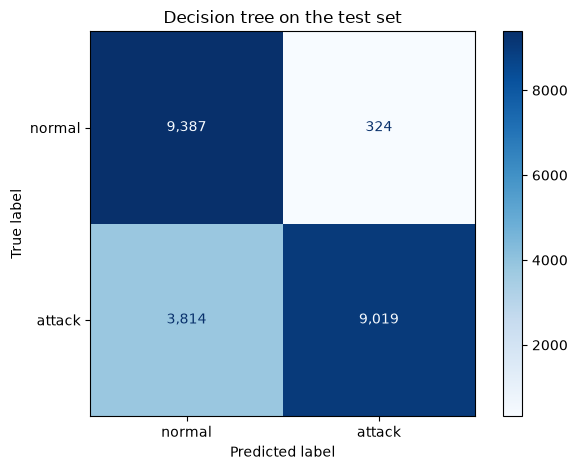

In [32]:
# (Optional) Confusion matrix as a chart for the README
disp = ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=['normal', 'attack'],
                                               cmap='Blues', values_format=',')
disp.ax_.set_title("Decision tree on the test set")
plt.tight_layout()
plt.savefig(IMG_DIR / "confusion_matrix.png", dpi=150)
plt.show()

## Phase 9: Model 2, Random Forest (100 trees that vote)

In [33]:
rf = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42, n_jobs=-1)   # n_jobs=-1: use all CPU cores
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)
print(classification_report(y_test, y_pred_rf, target_names=['normal', 'attack']))

              precision    recall  f1-score   support

      normal       0.65      0.97      0.78      9711
      attack       0.97      0.61      0.75     12833

    accuracy                           0.77     22544
   macro avg       0.81      0.79      0.76     22544
weighted avg       0.83      0.77      0.76     22544



## Phase 10: Where do the models fail?

For attack rows, the prediction is 1 when caught and 0 when missed, so the **mean of the predictions is the share caught (recall)**.

In [34]:
check = test[['label', 'attack_category', 'target']].copy()
check['rule'] = y_pred_rule.values
check['tree'] = y_pred
check['forest'] = y_pred_rf

attacks = check[check['target'] == 1].copy()                                 # real attacks only
attacks['seen_in_train'] = attacks['label'].isin(train['label'].unique())   # False = attack type never seen in training

In [35]:
recall_by_family = attacks.groupby('attack_category')[['rule', 'tree', 'forest']].mean().round(3)
recall_by_family['rows'] = attacks['attack_category'].value_counts()
recall_by_family   # DoS and Probe are caught well; R2L and U2R mostly slip through

,rule,tree,forest,rows
attack_category,,,,
DoS,0.763,0.859,0.781,7458
Probe,0.710,0.811,0.741,2421
R2L,0.053,0.218,0.062,2887
U2R,0.000,0.269,0.134,67


In [36]:
attacks.groupby('seen_in_train')[['rule', 'tree', 'forest']].agg(['mean', 'count']).round(3)   # False row count should be 3,750

rule         tree       forest      
                mean count   mean count   mean count
seen_in_train                                       
False          0.574  3750  0.434  3750  0.217  3750
True           0.596  9083  0.814  9083  0.770  9083

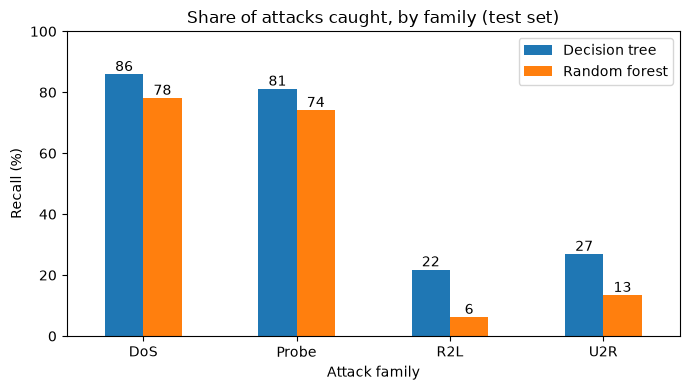

In [37]:
# (Optional) Recall by family as a chart for the README
ax = recall_by_family[['tree', 'forest']].mul(100).plot.bar(figsize=(7, 4), rot=0)
ax.set_title("Share of attacks caught, by family (test set)")
ax.set_ylabel("Recall (%)")
ax.set_xlabel("Attack family")
ax.set_ylim(0, 100)
ax.legend(["Decision tree", "Random forest"])
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f")
plt.tight_layout()
plt.savefig(IMG_DIR / "recall_by_family.png", dpi=150)
plt.show()

## Phase 11: Summary and extra insight (Optional)

In [38]:
# (Optional) All three approaches side by side
results = pd.DataFrame({
    name: {
        'accuracy': accuracy_score(y_test, pred),
        'precision (attack)': precision_score(y_test, pred),
        'recall (attack)': recall_score(y_test, pred),
        'recall on unseen attack types': attacks.loc[~attacks['seen_in_train'], col].mean(),
    }
    for name, pred, col in [('Rule: flag != SF', y_pred_rule, 'rule'),
                            ('Decision tree', y_pred, 'tree'),
                            ('Random forest', y_pred_rf, 'forest')]
}).T.round(3)
results

,accuracy,precision (attack),recall (attack),recall on unseen attack types
Rule: flag != SF,0.762,0.986,0.589,0.574
Decision tree,0.816,0.965,0.703,0.434
Random forest,0.765,0.967,0.609,0.217


In [39]:
# (Optional) Which features did the decision tree rely on most?
importances = pd.Series(model.feature_importances_, index=X_train.columns).nlargest(10)
importances.round(3)

src_bytes                 0.739
service_ecr_i             0.075
service_http              0.056
dst_host_same_srv_rate    0.028
dst_bytes                 0.022
hot                       0.022
logged_in                 0.010
service_ftp_data          0.007
dst_host_srv_count        0.004
protocol_type_tcp         0.004
dtype: float64

## Conclusions

My results (the README holds the full write-up):

- A one-line rule (`flag != 'SF'`) reaches **76% accuracy** with 98.6% precision. The loud attacks give themselves away through abnormal TCP connection states.
- The decision tree reaches **82% test accuracy**, and **97% of its alerts are real attacks**, but it **misses 30% of attacks**: mostly **R2L and U2R**, which made up under 1% of the training data, and attack types it never saw in training.
- The random forest scores lower overall (77%) and catches only **22% of unseen attack types**, half the tree's 43%.
- The simple rule catches the most unseen attack types (57%). A rule based on behaviour (an abnormal connection) generalises better than models that learned the exact shape of past attacks.
- The tree relies heavily on one feature, `src_bytes` (74% of its importance). That likely explains why new attacks with different traffic sizes slip through.